<a href="https://colab.research.google.com/github/alienplus/Alzheimer-s-Early-Stage-Computer-Aided-Diagnosis-CAD-using-ML-and-DL-Algorithms/blob/main/Power_BI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("enrollment_funnel_leads.csv",
                 parse_dates=["created_date","first_contact_date","application_date","admit_date","enroll_date"])
print(df.shape)
df.head()

(1605, 11)


,lead_id,created_date,source,program,school_type,counselor,first_contact_date,application_date,admit_date,enroll_date,follow_ups
0,L1059,2026-03-02,Google Ads,Business Administration,IGCSE,Counselor C,2026-03-02,NaT,NaT,NaT,6
1,L1469,2026-03-02,Meta Ads,Computer Science,Azhar/Other,Counselor C,2026-03-03,NaT,NaT,NaT,1
2,L1487,2026-03-02,Referral,Business Administration,IGCSE,Counselor A,2026-03-02,NaT,NaT,NaT,5
3,L1944,2026-03-02,Google Ads,Computer Science,IB,Counselor C,2026-03-04,NaT,NaT,NaT,3
4,L2482,2026-03-02,Meta Ads,Business Administration,IB,Counselor F,2026-03-04,NaT,NaT,NaT,3


In [2]:
df = df.drop_duplicates(subset="lead_id", keep="first")
missing = df["source"].isna()
bad_dates = ((df.first_contact_date < df.created_date) | (df.application_date < df.created_date) |
             (df.admit_date < df.application_date) | (df.enroll_date < df.admit_date))
clean = df[~missing & ~bad_dates].copy()
print(len(df), "after duplicates removed |", missing.sum(), "missing source |", bad_dates.sum(), "date errors |", len(clean), "clean rows")

1600 after duplicates removed | 3 missing source | 4 date errors | 1593 clean rows


Leads        1593
Contacted    1454
Applied       284
Admitted      217
Enrolled      117
dtype: int64
Leads        100.0
Contacted     91.3
Applied       17.8
Admitted      13.6
Enrolled       7.3
dtype: float64


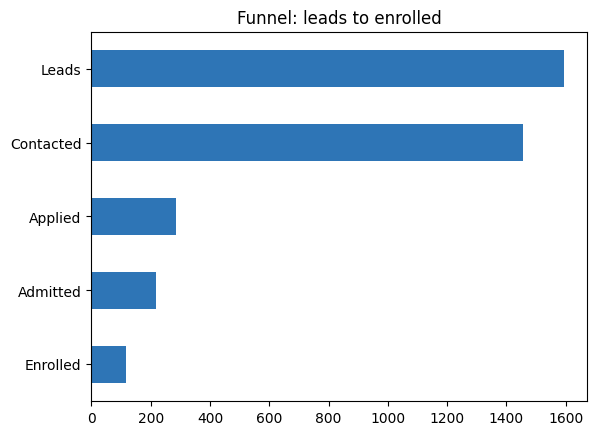

In [3]:
clean["days_to_contact"] = (clean.first_contact_date - clean.created_date).dt.days
funnel = pd.Series({"Leads": len(clean),
                    "Contacted": clean.first_contact_date.notna().sum(),
                    "Applied": clean.application_date.notna().sum(),
                    "Admitted": clean.admit_date.notna().sum(),
                    "Enrolled": clean.enroll_date.notna().sum()})
print(funnel)
print((funnel / funnel["Leads"] * 100).round(1))
ax = funnel.plot(kind="barh", color="#2E75B6")
ax.invert_yaxis()
plt.title("Funnel: leads to enrolled")
plt.show()

,leads,applications,enrolled,avg_days_to_contact,lead_to_enrolled_pct
source,,,,,
Walk-in,111,42,17,1.6,15.3
Referral,196,56,29,1.5,14.8
School Visit,251,54,20,1.6,8.0
Education Fair,145,30,11,1.7,7.6
Google Ads,253,28,14,1.5,5.5
Meta Ads,434,49,19,1.4,4.4
Website Organic,203,25,7,1.9,3.4


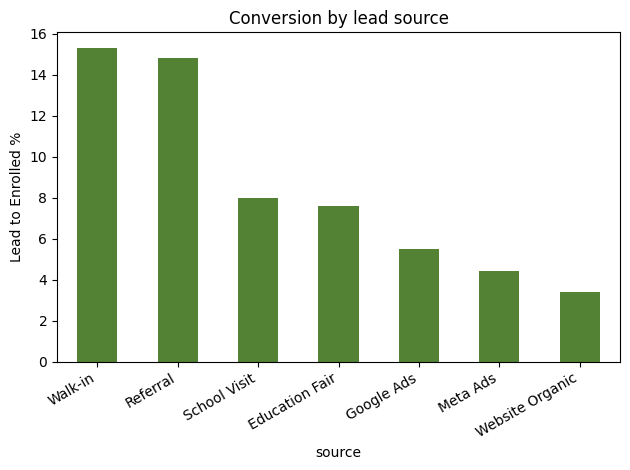

In [4]:
by_source = clean.groupby("source").agg(leads=("lead_id","count"),
                                        applications=("application_date","count"),
                                        enrolled=("enroll_date","count"),
                                        avg_days_to_contact=("days_to_contact","mean"))
by_source["lead_to_enrolled_pct"] = (by_source.enrolled / by_source.leads * 100).round(1)
by_source = by_source.sort_values("lead_to_enrolled_pct", ascending=False)
display(by_source.round(1))

by_source["lead_to_enrolled_pct"].plot(kind="bar", color="#548235")
plt.ylabel("Lead to Enrolled %")
plt.title("Conversion by lead source")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [5]:
contacted = clean[clean.days_to_contact.notna()]
speed = contacted.groupby(contacted.days_to_contact <= 2).agg(leads=("lead_id","count"),
                                                              applications=("application_date","count"))
speed["lead_to_app_pct"] = (speed.applications / speed.leads * 100).round(1)
speed.index = ["More than 2 days", "Within 2 days"]
display(speed)

,leads,applications,lead_to_app_pct
More than 2 days,301,46,15.3
Within 2 days,1153,238,20.6


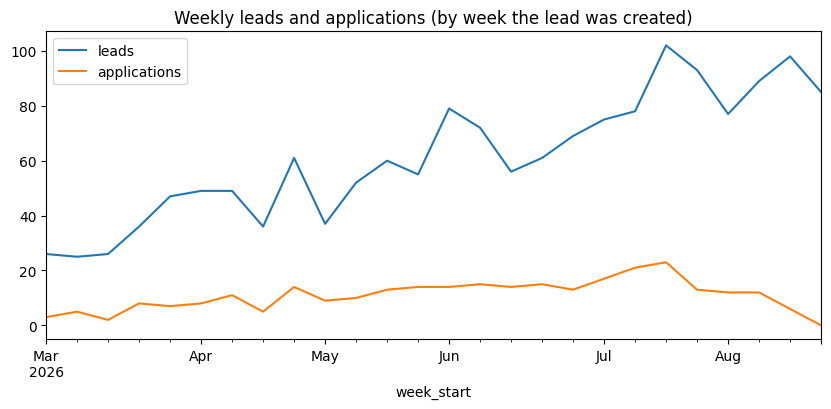

In [6]:
clean["week_start"] = clean.created_date - pd.to_timedelta(clean.created_date.dt.weekday, unit="D")
weekly = clean.groupby("week_start").agg(leads=("lead_id","count"), applications=("application_date","count"))
weekly.plot(figsize=(10, 4))
plt.title("Weekly leads and applications (by week the lead was created)")
plt.show()

In [7]:
x = np.arange(len(weekly))
slope, intercept = np.polyfit(x, weekly["leads"], 1)   # straight-line trend
future = np.arange(len(weekly), len(weekly) + 4)
print("Forecast leads, next 4 weeks:", (slope * future + intercept).round().astype(int))

Forecast leads, next 4 weeks: [ 98 101 103 106]
